In [1]:
# --- PHASE 1: SETUP & SPLIT ---
!pip install split-folders
from google.colab import drive
import zipfile, os, shutil, splitfolders

drive.mount('/content/drive')
zip_path = '/content/drive/MyDrive/Brinjal_Final_Dataset.zip'
extract_path = '/content/dataset_densenet_pure'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

base_extracted_dir = extract_path
unhealthy_dir = os.path.join(base_extracted_dir, 'Unhealthy_Leaves')

if os.path.exists(unhealthy_dir):
    for folder_name in os.listdir(unhealthy_dir):
        shutil.move(os.path.join(unhealthy_dir, folder_name), os.path.join(base_extracted_dir, folder_name))
    os.rmdir(unhealthy_dir)

output_dir = '/content/split_dataset_densenet_pure'
splitfolders.ratio(base_extracted_dir, output=output_dir, seed=42, ratio=(0.7, 0.15, 0.15), group_prefix=None)
print("Data splitting complete.")

Mounted at /content/drive


Copying files: 850 files [00:00, 7274.19 files/s]

Data splitting complete.


In [2]:
# --- PHASE 2: GENERATORS ---
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.densenet import preprocess_input

IMG_WIDTH, IMG_HEIGHT = 224, 224
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=30, width_shift_range=0.1, height_shift_range=0.1,
    zoom_range=0.2, horizontal_flip=True, fill_mode='nearest'
)
val_test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_generator = train_datagen.flow_from_directory(
    '/content/split_dataset_densenet_pure/train', target_size=(IMG_WIDTH, IMG_HEIGHT), batch_size=BATCH_SIZE, class_mode='categorical')
validation_generator = val_test_datagen.flow_from_directory(
    '/content/split_dataset_densenet_pure/val', target_size=(IMG_WIDTH, IMG_HEIGHT), batch_size=BATCH_SIZE, class_mode='categorical', shuffle=False)
test_generator = val_test_datagen.flow_from_directory(
    '/content/split_dataset_densenet_pure/test', target_size=(IMG_WIDTH, IMG_HEIGHT), batch_size=BATCH_SIZE, class_mode='categorical', shuffle=False)
class_labels = list(train_generator.class_indices.keys())

Found 595 images belonging to 3 classes.
Found 127 images belonging to 3 classes.
Found 128 images belonging to 3 classes.


In [3]:
# --- PHASE 3: DENSENET121 MODEL ---
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

base_model = DenseNet121(weights='imagenet', include_top=False, input_shape=(IMG_WIDTH, IMG_HEIGHT, 3))
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = BatchNormalization()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
predictions = Dense(3, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)
model.compile(optimizer=Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])

early_stop = EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)
lr_reduction = ReduceLROnPlateau(monitor='val_loss', patience=3, factor=0.5, min_lr=0.00001)

history = model.fit(train_generator, epochs=35, validation_data=validation_generator, callbacks=[early_stop, lr_reduction])

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/35
19/19 ━━━━━━━━━━━━━━━━━━━━ 79s 3s/step - accuracy: 0.6289 - loss: 0.9282 - val_accuracy: 0.9291 - val_loss: 0.2432 - learning_rate: 0.0010
Epoch 2/35
19/19 ━━━━━━━━━━━━━━━━━━━━ 9s 485ms/step - accuracy: 0.9357 - loss: 0.1947 - val_accuracy: 0.8898 - val_loss: 0.2747 - learning_rate: 0.0010
Epoch 3/35
19/19 ━━━━━━━━━━━━━━━━━━━━ 8s 398ms/step - accuracy: 0.9322 - loss: 0.1934 - val_accuracy: 0.9213 - val_loss: 0.2222 - learning_rate: 0.0010
Epoch 4/35
19/19 ━━━━━━━━━━━━━━━━━━━━ 9s 497ms/step - accuracy: 0.9520 - loss: 0.2136 - val_accuracy: 0.9370 - val_loss: 0.1675 - learning_rate: 0.0010
Epoch 5/35
19/19 ━━━━━━━━━━━━━━━━━━━━ 8s 417ms/step - accuracy: 0.9478 - loss: 0.1423 - val_accuracy: 0.9449 - val_loss: 0.1682 - learning_rate: 0.0010
Epoch 6/35
19/19 ━━━━━━━━━━━━━━━━━━━━ 8s 432ms/step - accuracy: 0.9668 - loss: 0.1115 - val_accuracy: 0.9528 - val_loss: 0.1403 - learning_rate: 0.0010
Epoch 7/35
19/19 ━━━━━━━━━━━━━━━━━━━━ 9s 491ms/step - accuracy: 0.9541 - loss: 0.1074 - va

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


4/4 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step

Test Accuracy: 92.97%

--- Classification Report ---
                   precision    recall  f1-score   support

  Healthy_Leaves       0.94      1.00      0.97        60
     Little_Leaf       0.92      0.77      0.84        30
Phomopsis_Blight       0.92      0.95      0.94        38

        accuracy                           0.93       128
       macro avg       0.93      0.90      0.91       128
    weighted avg       0.93      0.93      0.93       128



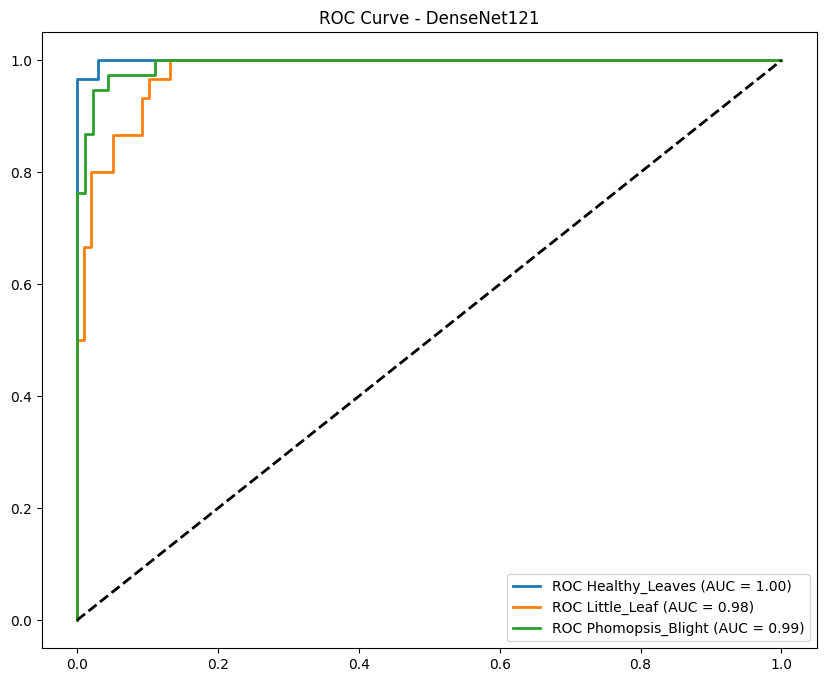

In [4]:
# --- PHASE 4 & 5: EVALUATION & ROC ---
import numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, accuracy_score
from sklearn.preprocessing import label_binarize

test_generator.reset()
Y_pred_prob = model.predict(test_generator)
y_pred_classes = np.argmax(Y_pred_prob, axis=1)
y_true = test_generator.classes

print(f"\nTest Accuracy: {accuracy_score(y_true, y_pred_classes) * 100:.2f}%")
print("\n--- Classification Report ---\n", classification_report(y_true, y_pred_classes, target_names=class_labels))

y_true_bin = label_binarize(y_true, classes=[0, 1, 2])
plt.figure(figsize=(10, 8))
for i in range(3):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], Y_pred_prob[:, i])
    plt.plot(fpr, tpr, lw=2, label=f'ROC {class_labels[i]} (AUC = {auc(fpr, tpr):.2f})')
plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.title('ROC Curve - DenseNet121')
plt.legend(loc="lower right")
plt.show()

In [5]:
# --- PHASE 6: EXPORT STATS ---
from google.colab import files
import pickle

model.save('densenet121_pure_3class.h5')
files.download('densenet121_pure_3class.h5')

densenet_test_results = {'model_name': 'DenseNet121', 'y_true': y_true, 'y_pred_prob': Y_pred_prob, 'y_pred_classes': y_pred_classes, 'class_labels': class_labels}
with open('densenet_test_results.pkl', 'wb') as f: pickle.dump(densenet_test_results, f)
files.download('densenet_test_results.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>